# DS-A4 | Model Comparison and Calibration Lab
## Predicting adult Red Knot sex: model comparison, probability calibration and threshold selection

**Name:** Kseniia Mamushkina  
**Student ID:** 2026A8010351001

### Research question

How do logistic regression, random forest and gradient boosting compare
in discriminating between male and female adult Red Knots and producing
reliable probabilities, and how should a decision threshold be selected
under explicit error costs and resource constraints?

### Dataset

The analysis uses adult Red Knots (*Calidris canutus canutus*) captured
at Banc d'Arguin, Mauritania.

Source: Oortwijn et al. (2025), Dryad.  
https://doi.org/10.5061/dryad.3n5tb2rqb

Source file: `14._adults_Mauritania.csv`.

- Unit of analysis: one individual bird.
- Reference outcome: sex determined by DNA analysis.
- Positive class: female (`F = 1`).
- Negative class: male (`M = 0`).
- Predictors: wing, bill and diagonal tarsus lengths, in millimetres.
- Individual identifier: `Ring`.
- Sampling metadata: `Year` and `Month`.

All three models will use the same predictors.
Ring identifiers and sampling metadata will not be used as predictors.

### Relationship to DS-A3

This assignment reuses the dataset and data-cleaning rules from DS-A3.
The new analysis focuses on model comparison, probability calibration
and decision thresholds.

The dataset, including the previous test results, has already been
examined in DS-A3. The evaluation protocol for DS-A4 will be specified before fitting and comparing the new candidate models.

In [ ]:
from pathlib import Path
import hashlib

import numpy as np
import pandas as pd
from IPython.display import display

DATA_PATH = Path("/content/14._adults_Mauritania.csv")

if not DATA_PATH.is_file():
    raise FileNotFoundError(
        "Upload 14._adults_Mauritania.csv to the Colab Files panel."
    )

# Verify that the input is the same source file used in DS-A3.
data_sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()

EXPECTED_SHA256 = (
    "6da0a6b44266f448393c92a293f24f145"
    "d803ee95b6246804a0185bbfd9869f6"
)

print("Filename:", DATA_PATH.name)
print("File size (bytes):", DATA_PATH.stat().st_size)
print("SHA-256:", data_sha256)

if data_sha256 != EXPECTED_SHA256:
    raise ValueError(
        "The file differs from the DS-A3 source. "
        "Check its version before continuing."
    )

df_raw = pd.read_csv(
    DATA_PATH,
    dtype={"Ring": "string", "Sex": "string"}
)

EXPECTED_COLUMNS = [
    "Ring", "Year", "Month", "Sex", "Wing", "Bill", "Tarsus"
]

if df_raw.columns.tolist() != EXPECTED_COLUMNS:
    raise ValueError("Unexpected column names or column order.")

print("\nRaw data shape:", df_raw.shape)
display(df_raw.head())

Filename: 14._adults_Mauritania.csv
File size (bytes): 69868
SHA-256: 6da0a6b44266f448393c92a293f24f145d803ee95b6246804a0185bbfd9869f6

Raw data shape: (2165, 7)


,Ring,Year,Month,Sex,Wing,Bill,Tarsus
0,Z023161,2003,12,M,169,32.9,32.8
1,Z023672,2003,12,M,164,32.4,32.4
2,Z023867,2003,12,M,166,36.6,31.8
3,Z023870,2003,12,F,167,38.3,33.2
4,Z023871,2003,12,M,166,35.0,32.5


## 1. Data preparation

The preparation rules are carried forward from DS-A3:

1. Check the schema, missing values, sex labels and numeric measurements.
2. Exclude all records for individuals with conflicting reference-sex labels.
3. Retain the earliest capture of each remaining individual, ordered by
   Year and Month. Original row order breaks ties within the same month.
4. Retain excluded records and their exclusion reasons for auditing.
5. Use Wing, Bill and Tarsus as predictors, with female coded as 1.

No records will be excluded solely because their measurements are unusual.

The source dataframe remains unchanged. No scaling, model fitting
or data splitting is performed in this section.

In [ ]:
FEATURES = ["Wing", "Bill", "Tarsus"]

print("Missing values by column:")
display(df_raw.isna().sum().to_frame("missing"))

print("Fully duplicated rows:", df_raw.duplicated().sum())

print("\nRaw sex counts:")
display(df_raw["Sex"].value_counts(dropna=False).to_frame("records"))

# Stop rather than silently discard or alter unexpected data.
if df_raw.isna().any().any():
    raise ValueError("Missing values detected. Review before continuing.")

if not df_raw["Sex"].isin(["F", "M"]).all():
    raise ValueError("Unexpected sex labels detected.")

for column in ["Year", "Month"] + FEATURES:
    values = pd.to_numeric(df_raw[column], errors="raise")
    if not np.isfinite(values.to_numpy(dtype=float)).all():
        raise ValueError(f"Non-finite values detected in {column}.")

if not df_raw["Month"].between(1, 12).all():
    raise ValueError("Invalid month values detected.")

if not (df_raw[FEATURES] > 0).all().all():
    raise ValueError("Non-positive measurements detected.")

# Preserve original row order for traceability and date ties.
working = df_raw.copy()
working["source_row"] = np.arange(1, len(working) + 1)

# Identify individuals with conflicting reference-sex labels.
sex_per_ring = working.groupby("Ring")["Sex"].nunique()
conflicting_rings = sex_per_ring[sex_per_ring > 1].index

excluded_conflicts = working[
    working["Ring"].isin(conflicting_rings)
].copy()
excluded_conflicts["exclusion_reason"] = "conflicting_reference_sex"

remaining = working[
    ~working["Ring"].isin(conflicting_rings)
].copy()

# Keep the earliest record per individual.
remaining = remaining.sort_values(
    ["Year", "Month", "source_row"]
)

later_capture = remaining.duplicated("Ring", keep="first")

excluded_recaptures = remaining[later_capture].copy()
excluded_recaptures["exclusion_reason"] = "later_capture"

df = remaining[~later_capture].copy().reset_index(drop=True)

exclusions = pd.concat(
    [excluded_conflicts, excluded_recaptures],
    ignore_index=True
)

assert df["Ring"].is_unique
assert len(df) + len(exclusions) == len(df_raw)

print("\nIndividuals with conflicting sex labels:")
print(conflicting_rings.tolist())

print("\nRecords excluded because of conflicting sex:",
      len(excluded_conflicts))
print("Later capture records excluded:", len(excluded_recaptures))
print("Final number of birds:", len(df))

print("\nExclusion audit:")
display(exclusions)

Missing values by column:


,missing
Ring,0
Year,0
Month,0
Sex,0
Wing,0
Bill,0
Tarsus,0


Fully duplicated rows: 0

Raw sex counts:


,records
Sex,
F,1286
M,879



Individuals with conflicting sex labels:
['Z062234']

Records excluded because of conflicting sex: 2
Later capture records excluded: 33
Final number of birds: 2130

Exclusion audit:


,Ring,Year,Month,Sex,Wing,Bill,Tarsus,source_row,exclusion_reason
0,Z062234,2009,12,M,173,39.0,33.0,815,conflicting_reference_sex
1,Z062234,2021,4,F,174,38.0,33.2,1868,conflicting_reference_sex
2,Z024135,2004,12,F,181,37.8,35.3,89,later_capture
3,Z033672,2006,12,M,164,32.8,31.4,302,later_capture
4,Z033466,2007,12,M,174,31.5,30.2,434,later_capture
5,Z049560,2007,12,F,167,36.2,33.3,453,later_capture
6,Z032930,2008,4,F,176,34.5,31.6,543,later_capture
7,Z024765,2008,11,F,173,37.1,33.5,542,later_capture
8,Z048999,2008,11,M,168,34.3,33.1,544,later_capture
9,Z033451,2009,4,M,167,34.6,31.4,700,later_capture


In [ ]:
# Morphometric predictors only.
X = df[FEATURES].copy()

# Positive class: female.
y = df["Sex"].map({"M": 0, "F": 1}).astype(int)
y.name = "female"

# Retained separately for identification and later subgroup analysis.
metadata = df[["Ring", "Year", "Month"]].copy()

assert X.index.equals(y.index)
assert X.index.equals(metadata.index)
assert not X.isna().any().any()
assert set(y.unique()) == {0, 1}

class_summary = (
    df["Sex"]
    .value_counts()
    .reindex(["F", "M"], fill_value=0)
    .rename_axis("Sex")
    .to_frame("birds")
)
class_summary["proportion"] = class_summary["birds"] / len(df)

print("Predictors:", FEATURES)
print("X shape:", X.shape)
print("Target coding: F = 1, M = 0")

print("\nFinal class distribution:")
display(class_summary)

print("\nMeasurement summary (mm):")
display(X.describe().T)

Predictors: ['Wing', 'Bill', 'Tarsus']
X shape: (2130, 3)
Target coding: F = 1, M = 0

Final class distribution:


,birds,proportion
Sex,,
F,1263,0.592958
M,867,0.407042



Measurement summary (mm):


,count,mean,std,min,25%,50%,75%,max
Wing,2130.0,171.891549,4.598688,153.0,169.0,172.0,175.0,188.0
Bill,2130.0,35.365352,1.878809,28.6,34.1,35.4,36.6,41.3
Tarsus,2130.0,32.612488,1.362152,28.1,31.7,32.6,33.5,39.2


### Data preparation results

The source dataset contains 2,165 records, with no missing values
or fully duplicated rows.

Individual Z062234 has conflicting reference-sex labels; both records
were excluded. Among the remaining individuals, 33 later capture
records were excluded, retaining the earliest capture per bird.

The analytical sample contains 2,130 unique birds:
1,263 females (59.3%) and 867 males (40.7%).

The predictor matrix contains Wing, Bill and Tarsus.
The target is coded as female = 1 and male = 0.
Excluded records and their reasons are retained in `exclusions`.

## 2. Evaluation protocol

### Nested cross-validation

The analysis uses all 2,130 birds in a nested cross-validation procedure:

- Five stratified outer folds provide evaluation data.
- Three stratified inner folds select hyperparameters within each
  outer training subset.
- All three model families use identical outer and inner splits.
- The random seed is fixed at 42.

In each outer iteration, 1,704 birds are available for model development
and 426 birds are reserved for evaluation.

Within the outer training subset, each inner iteration uses
1,136 birds for fitting and 568 birds for validation.

After hyperparameter selection, the model is refitted on all
1,704 outer-training birds and evaluated on the 426 outer-validation birds.

Each bird receives one outer-fold prediction from each model family,
without being included in the training data used for that prediction.

### Information boundaries

Any learned preprocessing is fitted within the relevant training subset.
Hyperparameter selection, any probability calibration and threshold
selection use only the outer training data.

Outer validation labels are used for evaluation, not for choosing
settings or thresholds.

In [ ]:
from sklearn.model_selection import StratifiedKFold

SEED = 42
N_OUTER_FOLDS = 5
N_INNER_FOLDS = 3

# Shared outer splits for all model families.
outer_cv = StratifiedKFold(
    n_splits=N_OUTER_FOLDS,
    shuffle=True,
    random_state=SEED
)

outer_splits = list(outer_cv.split(X, y))

# Inner indices are relative to each outer training subset.
inner_splits = {}

# Record the outer validation fold assigned to each bird.
fold_manifest = metadata.copy()
fold_manifest["Sex"] = df["Sex"]
fold_manifest["y"] = y
fold_manifest["outer_fold"] = -1

validation_count = np.zeros(len(df), dtype=int)

for fold, (train_idx, valid_idx) in enumerate(
    outer_splits, start=1
):
    train_rings = set(metadata.iloc[train_idx]["Ring"])
    valid_rings = set(metadata.iloc[valid_idx]["Ring"])

    assert train_rings.isdisjoint(valid_rings)

    fold_manifest.loc[valid_idx, "outer_fold"] = fold
    validation_count[valid_idx] += 1

    inner_cv = StratifiedKFold(
        n_splits=N_INNER_FOLDS,
        shuffle=True,
        random_state=SEED
    )

    inner_splits[fold] = list(
        inner_cv.split(
            X.iloc[train_idx],
            y.iloc[train_idx]
        )
    )

    for inner_train, inner_valid in inner_splits[fold]:
        assert set(inner_train).isdisjoint(inner_valid)
        assert len(inner_train) + len(inner_valid) == len(train_idx)

# Check that every bird is evaluated exactly once.
assert (validation_count == 1).all()
assert fold_manifest["outer_fold"].between(
    1, N_OUTER_FOLDS
).all()

fold_summary = pd.crosstab(
    fold_manifest["outer_fold"],
    fold_manifest["Sex"]
).reindex(columns=["F", "M"], fill_value=0)

fold_summary["validation_total"] = fold_summary.sum(axis=1)
fold_summary["training_total"] = (
    len(df) - fold_summary["validation_total"]
)

print("Outer validation folds:")
display(fold_summary)

# Save reproducibility and audit files.
OUTPUT_DIR = Path("/content/ds_a4_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

fold_manifest.to_csv(
    OUTPUT_DIR / "outer_fold_manifest.csv",
    index=False
)

exclusions.to_csv(
    OUTPUT_DIR / "excluded_records.csv",
    index=False
)

print("Fold assignments and exclusion audit saved.")

Outer validation folds:


Sex,F,M,validation_total,training_total
outer_fold,,,,
1,252,174,426,1704
2,252,174,426,1704
3,253,173,426,1704
4,253,173,426,1704
5,253,173,426,1704


Fold assignments and exclusion audit saved.


### Candidate models and search budget

All candidates use the same three predictors: Wing, Bill and Tarsus.

1. Logistic regression provides the strong simple baseline.
   The predictors are standardized within the fitting pipeline.
   Six values of the inverse regularization strength C are compared:
   0.01, 0.1, 1, 10, 100 and 1000.

2. Random forest uses 300 trees.
   The search combines maximum depths of 3, 6 and unrestricted depth
   with minimum leaf sizes of 5 and 15, giving six configurations.

3. Gradient boosting uses a learning rate of 0.05
   and a minimum leaf size of 5.
   The search combines 50, 100 and 200 trees with maximum depths
   of 1 and 2, giving six configurations.

Each model family receives six configurations evaluated on the same
three inner folds. The budget is defined by the number of configurations
and validation fits, rather than equal runtime.

Within each outer training subset, the selected configuration is the
one with the lowest mean inner-validation Brier score.

No class weighting or resampling is applied.
Tree models use the original measurement scales.
Standardization for logistic regression is fitted only within the
relevant training subset.

These search spaces are specified before examining DS-A4 model results.
They are deliberately limited and do not represent an exhaustive search.

In [ ]:
import json
import sklearn

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.model_selection import ParameterGrid

# Define the candidate pipelines.
models = {
    "Logistic regression": Pipeline([
        ("scale", StandardScaler()),
        ("model", LogisticRegression(
            solver="lbfgs",
            max_iter=5000,
            class_weight=None,
            random_state=SEED
        ))
    ]),

    "Random forest": Pipeline([
        ("model", RandomForestClassifier(
            n_estimators=300,
            max_features="sqrt",
            bootstrap=True,
            class_weight=None,
            random_state=SEED,
            n_jobs=1
        ))
    ]),

    "Gradient boosting": Pipeline([
        ("model", GradientBoostingClassifier(
            loss="log_loss",
            learning_rate=0.05,
            min_samples_leaf=5,
            subsample=1.0,
            n_iter_no_change=None,
            random_state=SEED
        ))
    ])
}

# Six configurations per model family.
param_grids = {
    "Logistic regression": {
        "model__C": [0.01, 0.1, 1, 10, 100, 1000]
    },

    "Random forest": {
        "model__max_depth": [3, 6, None],
        "model__min_samples_leaf": [5, 15]
    },

    "Gradient boosting": {
        "model__n_estimators": [50, 100, 200],
        "model__max_depth": [1, 2]
    }
}

# GridSearchCV maximizes scores, so use negative Brier score.
TUNING_SCORING = "neg_brier_score"

# Check and record every planned configuration.
candidate_rows = []

for model_name, grid in param_grids.items():
    configurations = list(ParameterGrid(grid))

    assert len(configurations) == 6

    for config_id, parameters in enumerate(
        configurations, start=1
    ):
        candidate_rows.append({
            "model": model_name,
            "configuration_id": config_id,
            "parameters": json.dumps(parameters, sort_keys=True)
        })

candidate_table = pd.DataFrame(candidate_rows)

budget_summary = (
    candidate_table.groupby("model", sort=False)
    .size()
    .rename("configurations")
    .to_frame()
)

budget_summary["inner_folds"] = N_INNER_FOLDS
budget_summary["search_fits_per_outer_fold"] = (
    budget_summary["configurations"] * N_INNER_FOLDS
)

print("scikit-learn version:", sklearn.__version__)
print("Predictors:", FEATURES)
print("Tuning criterion: minimum mean validation Brier score")

display(budget_summary)

candidate_table.to_csv(
    OUTPUT_DIR / "candidate_configurations.csv",
    index=False
)

model_specification = {
    "seed": SEED,
    "features": FEATURES,
    "positive_class": "F",
    "tuning_scoring": TUNING_SCORING,
    "sklearn_version": sklearn.__version__,
    "parameter_grids": param_grids,
    "fixed_estimator_parameters": {
        name: pipeline.named_steps["model"].get_params(deep=False)
        for name, pipeline in models.items()
    },
    "logistic_scaler_parameters": (
        models["Logistic regression"]
        .named_steps["scale"]
        .get_params(deep=False)
    )
}

with open(
    OUTPUT_DIR / "model_specification.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(model_specification, file, indent=2)

print("Candidate configurations and model specification saved.")

scikit-learn version: 1.6.1
Predictors: ['Wing', 'Bill', 'Tarsus']
Tuning criterion: minimum mean validation Brier score


,configurations,inner_folds,search_fits_per_outer_fold
model,,,
Logistic regression,6,3,18
Random forest,6,3,18
Gradient boosting,6,3,18


Candidate configurations and model specification saved.


### Evaluation metrics

The primary metric is the Brier score, with lower values indicating
better probability predictions.

Additional metrics are ROC-AUC, average precision and binary ECE.
ECE uses 10 equal-width probability bins and compares mean predicted
female probability with observed female frequency within each bin.

ROC, precision–recall and calibration curves will be reported.

Accuracy, balanced accuracy, precision, recall and confusion matrices
will also be reported at the reference classification threshold of 0.50.

The primary analysis evaluates the probabilities produced by the
candidate models without an additional post-hoc calibration step.

### Hypothetical decision scenario

The operational task is to select likely females for subsequent
DNA confirmation under a limited verification capacity.

This is an illustrative scenario, not a description of actual project
costs or available laboratory capacity.

The reference scenario assigns:
- cost 1 to selecting a male (false positive);
- cost 2 to not selecting a female (false negative);
- zero loss to correct selections and non-selections;
- verification capacity of at most 40% of birds.

Total loss is FP + 2 × FN.

A bird is eligible for selection when its predicted female probability
is at least the chosen threshold. If eligible birds exceed capacity,
only those with the highest probabilities are selected.
Ring identifier in ascending order breaks probability ties.

Non-selection does not constitute an assertion that the bird is male.

### Threshold selection

For each model and outer fold, threshold selection uses inner
out-of-fold predictions from the selected configuration within the
outer training subset.

Candidate thresholds are 0.00 to 1.00 in increments of 0.01.
Selecting no birds is also considered.

The decision rule minimizes loss subject to the capacity constraint.
Ties are resolved by selecting fewer birds, then by choosing the
higher threshold.

The resulting rule is applied to the outer validation subset
without using its reference-sex labels for selection.

### Sensitivity analysis

The false-positive cost remains 1.
False-negative costs of 0.5, 1, 2 and 5 are examined.
Verification capacities of 20%, 40% and 60% are examined.

Each alternative rule is selected within the outer training data
and evaluated on the corresponding outer validation data.

In [ ]:
METRIC_CONFIG = {
    "primary_metric": "brier_score",
    "tuning_scoring": TUNING_SCORING,
    "additional_probability_metrics": [
        "roc_auc",
        "average_precision",
        "ece"
    ],
    "ece_n_bins": 10,
    "ece_bin_strategy": "equal_width",
    "reference_classification_threshold": 0.50,
    "posthoc_calibration": None
}

DECISION_CONFIG = {
    "scenario": "hypothetical_female_selection_for_DNA_confirmation",
    "false_positive_cost": 1.0,
    "false_negative_cost": 2.0,
    "capacity_fraction": 0.40,
    "threshold_grid": [
        round(float(t), 2)
        for t in np.linspace(0, 1, 101)
    ],
    "include_select_none": True,
    "capacity_rounding": "floor",
    "capacity_rule": "highest_probabilities_among_eligible",
    "probability_tie_break": "Ring_ascending",
    "decision_tie_break": [
        "lower_cost",
        "fewer_selected",
        "higher_threshold"
    ]
}

SENSITIVITY_CONFIG = {
    "false_positive_cost": 1.0,
    "false_negative_costs": [0.5, 1.0, 2.0, 5.0],
    "capacity_fractions": [0.20, 0.40, 0.60]
}

evaluation_protocol = {
    "data_sha256": data_sha256,
    "n_birds": len(df),
    "features": FEATURES,
    "target": {"female": 1, "male": 0},
    "seed": SEED,
    "outer_folds": N_OUTER_FOLDS,
    "inner_folds": N_INNER_FOLDS,
    "fold_manifest_sha256": hashlib.sha256(
        (OUTPUT_DIR / "outer_fold_manifest.csv").read_bytes()
    ).hexdigest(),
    "model_specification": model_specification,
    "metrics": METRIC_CONFIG,
    "decision": DECISION_CONFIG,
    "sensitivity": SENSITIVITY_CONFIG
}

with open(
    OUTPUT_DIR / "evaluation_protocol.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(evaluation_protocol, file, indent=2)

print("Metric and decision rules saved.")
print("Primary metric:", METRIC_CONFIG["primary_metric"])
print("Reference FP cost:", DECISION_CONFIG["false_positive_cost"])
print("Reference FN cost:", DECISION_CONFIG["false_negative_cost"])
print("Reference capacity:", DECISION_CONFIG["capacity_fraction"])
print(
    "Sensitivity scenarios:",
    len(SENSITIVITY_CONFIG["false_negative_costs"])
    * len(SENSITIVITY_CONFIG["capacity_fractions"])
)

Metric and decision rules saved.
Primary metric: brier_score
Reference FP cost: 1.0
Reference FN cost: 2.0
Reference capacity: 0.4
Sensitivity scenarios: 12


## 3. Nested cross-validation execution

For each model family and outer fold:

1. Evaluate the six predefined configurations using the shared
   inner folds and select the configuration with the lowest
   mean validation Brier score.
2. Generate inner out-of-fold probabilities for the selected
   configuration. These predictions are reserved for decision-rule
   development within the outer training subset.
3. Refit the selected configuration on the full outer training subset.
4. Predict female probabilities for the outer validation subset.

The inner predictions are tuning data, not an independent estimate
of the performance of the selected configuration.

Outer predictions are retained for paired model evaluation.
Each bird receives exactly one outer prediction from each model family.

All search results, selected parameters, warnings and any execution
errors are retained.

In [ ]:
import time
import traceback
import warnings
from datetime import datetime, timezone

from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, cross_val_predict
from sklearn.metrics import brier_score_loss

# Keep separate execution folders so reruns retain earlier evidence.
run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
RUN_DIR = OUTPUT_DIR / "cv_runs" / run_id
RUN_DIR.mkdir(parents=True, exist_ok=False)

with open(
    RUN_DIR / "evaluation_protocol.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(evaluation_protocol, file, indent=2)

model_slugs = {
    "Logistic regression": "lr",
    "Random forest": "rf",
    "Gradient boosting": "gb"
}

# One row per bird; model probabilities will occupy separate columns.
outer_predictions = fold_manifest.copy()

for slug in model_slugs.values():
    outer_predictions[f"p_{slug}"] = np.nan

inner_predictions = {}
training_records = []

total_runs = len(models) * N_OUTER_FOLDS
run_number = 0

for fold, (train_idx, valid_idx) in enumerate(
    outer_splits, start=1
):
    X_train = X.iloc[train_idx]
    y_train = y.iloc[train_idx]
    X_valid = X.iloc[valid_idx]

    for model_name, pipeline in models.items():
        run_number += 1
        slug = model_slugs[model_name]
        prefix = f"{slug}_fold_{fold}"
        started = time.perf_counter()
        caught_warnings = []

        print(
            f"[{run_number}/{total_runs}] "
            f"{model_name} | outer fold {fold}",
            flush=True
        )

        try:
            with warnings.catch_warnings(record=True) as caught_warnings:
                warnings.simplefilter("always")

                search = GridSearchCV(
                    estimator=clone(pipeline),
                    param_grid=param_grids[model_name],
                    scoring=TUNING_SCORING,
                    cv=inner_splits[fold],
                    refit=True,
                    n_jobs=1,
                    error_score="raise",
                    return_train_score=False
                )

                search.fit(X_train, y_train)

                # Retain results for all six configurations.
                pd.DataFrame(search.cv_results_).to_csv(
                    RUN_DIR / f"{prefix}_search_results.csv",
                    index=False
                )

                # Verify probability column order: male, female.
                assert np.array_equal(
                    search.best_estimator_.classes_,
                    np.array([0, 1])
                )

                # Internal tuning predictions for later threshold selection.
                p_inner = cross_val_predict(
                    estimator=clone(search.best_estimator_),
                    X=X_train,
                    y=y_train,
                    cv=inner_splits[fold],
                    method="predict_proba",
                    n_jobs=1
                )[:, 1]

                # Predictions on the external evaluation fold.
                p_outer = search.best_estimator_.predict_proba(
                    X_valid
                )[:, 1]

                for probabilities in [p_inner, p_outer]:
                    assert np.isfinite(probabilities).all()
                    assert (
                        (probabilities >= 0)
                        & (probabilities <= 1)
                    ).all()

            inner_table = metadata.iloc[train_idx].copy()
            inner_table["y"] = y_train.to_numpy()
            inner_table["p_female"] = p_inner
            inner_table["outer_fold"] = fold
            inner_table["model"] = model_name

            inner_predictions[(model_name, fold)] = inner_table

            inner_table.to_csv(
                RUN_DIR / f"{prefix}_inner_predictions.csv",
                index=False
            )

            outer_predictions.loc[
                valid_idx, f"p_{slug}"
            ] = p_outer

            training_records.append({
                "model": model_name,
                "outer_fold": fold,
                "best_inner_brier": -float(search.best_score_),
                "best_parameters": json.dumps(
                    search.best_params_, sort_keys=True
                ),
                "elapsed_seconds": time.perf_counter() - started
            })

            # Save progress after every completed model/fold.
            pd.DataFrame(training_records).to_csv(
                RUN_DIR / "training_records.csv",
                index=False
            )

            outer_predictions.to_csv(
                RUN_DIR / "outer_predictions.csv",
                index=False
            )

            print("  Completed.", flush=True)

        except Exception:
            (RUN_DIR / f"{prefix}_error.txt").write_text(
                traceback.format_exc(),
                encoding="utf-8"
            )
            raise

        finally:
            warning_records = [
                {
                    "category": item.category.__name__,
                    "message": str(item.message)
                }
                for item in caught_warnings
            ]

            with open(
                RUN_DIR / f"{prefix}_warnings.json",
                "w",
                encoding="utf-8"
            ) as file:
                json.dump(warning_records, file, indent=2)

            if warning_records:
                print(
                    f"  Warnings recorded: {len(warning_records)}",
                    flush=True
                )

# Confirm complete paired predictions.
probability_columns = [
    f"p_{slug}" for slug in model_slugs.values()
]

assert len(outer_predictions) == len(df)
assert outer_predictions["Ring"].is_unique
assert outer_predictions[probability_columns].notna().all().all()

training_results = pd.DataFrame(training_records)

# Initial comparison using only outer-fold probabilities.
brier_comparison = pd.DataFrame([
    {
        "model": model_name,
        "outer_brier": brier_score_loss(
            outer_predictions["y"],
            outer_predictions[f"p_{slug}"]
        )
    }
    for model_name, slug in model_slugs.items()
]).sort_values("outer_brier").reset_index(drop=True)

brier_comparison.to_csv(
    RUN_DIR / "initial_brier_comparison.csv",
    index=False
)

print("\nCompleted model/fold runs:", len(training_results))
print("Birds with predictions from every model:", len(outer_predictions))
print("\nInitial outer-fold Brier comparison:")
display(brier_comparison)

print("Execution results saved in:", RUN_DIR)

[1/15] Logistic regression | outer fold 1
  Completed.
  Warnings recorded: 22
[2/15] Random forest | outer fold 1
  Completed.
[3/15] Gradient boosting | outer fold 1
  Completed.
[4/15] Logistic regression | outer fold 2
  Completed.
  Warnings recorded: 22
[5/15] Random forest | outer fold 2
  Completed.
[6/15] Gradient boosting | outer fold 2
  Completed.
[7/15] Logistic regression | outer fold 3
  Completed.
  Warnings recorded: 22
[8/15] Random forest | outer fold 3
  Completed.
[9/15] Gradient boosting | outer fold 3
  Completed.
[10/15] Logistic regression | outer fold 4
  Completed.
  Warnings recorded: 22
[11/15] Random forest | outer fold 4
  Completed.
[12/15] Gradient boosting | outer fold 4
  Completed.
[13/15] Logistic regression | outer fold 5
  Completed.
  Warnings recorded: 22
[14/15] Random forest | outer fold 5
  Completed.
[15/15] Gradient boosting | outer fold 5
  Completed.

Completed model/fold runs: 15
Birds with predictions from every model: 2130

Initial out

,model,outer_brier
0,Logistic regression,0.158644
1,Gradient boosting,0.160398
2,Random forest,0.161964


Execution results saved in: /content/ds_a4_outputs/cv_runs/20261109T123028_334651Z


In [ ]:
warning_rows = []

for path in sorted(RUN_DIR.glob("*_warnings.json")):
    with open(path, encoding="utf-8") as file:
        records = json.load(file)

    for record in records:
        warning_rows.append({
            "category": record["category"],
            "message": record["message"]
        })

if warning_rows:
    warning_summary = (
        pd.DataFrame(warning_rows)
        .groupby(["category", "message"])
        .size()
        .reset_index(name="count")
    )

    for row in warning_summary.itertuples(index=False):
        print(f"{row.category} | total occurrences: {row.count}")
        print(row.message)
        print()
else:
    print("No warnings recorded.")

DeprecationWarning | total occurrences: 110
scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.



### Execution checks

All 15 model-family/outer-fold runs completed, producing paired
outer-fold predictions for all 2,130 birds.

The warning log contains 110 repetitions of a SciPy DeprecationWarning
concerning the `disp` and `iprint` options of L-BFGS-B.
These are deprecated output-control options, not convergence failures.

No other warning types were recorded.
The warnings are retained with the execution results.

## 4. Model performance

Performance is assessed using paired outer-fold predictions.
Pooled metrics and fold-specific results are retained.

In [ ]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix
)

def binary_ece(y_true, probabilities, n_bins=10):
    y_true = np.asarray(y_true, dtype=int)
    probabilities = np.asarray(probabilities, dtype=float)

    # Equal-width bins; probability 1 belongs to the final bin.
    bin_ids = np.minimum(
        (probabilities * n_bins).astype(int),
        n_bins - 1
    )

    ece = 0.0

    for bin_id in range(n_bins):
        mask = bin_ids == bin_id

        if mask.any():
            mean_probability = probabilities[mask].mean()
            observed_frequency = y_true[mask].mean()

            ece += mask.mean() * abs(
                mean_probability - observed_frequency
            )

    return float(ece)


def evaluate_probabilities(y_true, probabilities):
    y_true = np.asarray(y_true, dtype=int)
    probabilities = np.asarray(probabilities, dtype=float)

    threshold = METRIC_CONFIG["reference_classification_threshold"]
    predicted = (probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, predicted, labels=[0, 1]
    ).ravel()

    return {
        "brier": brier_score_loss(y_true, probabilities),
        "ece": binary_ece(
            y_true,
            probabilities,
            n_bins=METRIC_CONFIG["ece_n_bins"]
        ),
        "roc_auc": roc_auc_score(y_true, probabilities),
        "average_precision": average_precision_score(
            y_true, probabilities
        ),
        "accuracy": accuracy_score(y_true, predicted),
        "balanced_accuracy": balanced_accuracy_score(
            y_true, predicted
        ),
        "precision_F": precision_score(
            y_true, predicted, zero_division=0
        ),
        "recall_F": recall_score(
            y_true, predicted, pos_label=1, zero_division=0
        ),
        "recall_M": recall_score(
            y_true, predicted, pos_label=0, zero_division=0
        ),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp)
    }


overall_rows = []
fold_rows = []

for model_name, slug in model_slugs.items():
    probability_column = f"p_{slug}"

    overall_rows.append({
        "model": model_name,
        **evaluate_probabilities(
            outer_predictions["y"],
            outer_predictions[probability_column]
        )
    })

    for fold, subset in outer_predictions.groupby("outer_fold"):
        fold_rows.append({
            "model": model_name,
            "outer_fold": int(fold),
            **evaluate_probabilities(
                subset["y"],
                subset[probability_column]
            )
        })

model_summary = (
    pd.DataFrame(overall_rows)
    .set_index("model")
    .sort_values("brier")
)

fold_metrics = pd.DataFrame(fold_rows)

model_summary.to_csv(RUN_DIR / "model_metrics_pooled.csv")
fold_metrics.to_csv(
    RUN_DIR / "model_metrics_by_fold.csv",
    index=False
)

print("Probability quality and discrimination:")
display(
    model_summary[
        ["brier", "ece", "roc_auc", "average_precision"]
    ].round(4)
)

print("Classification at threshold 0.50:")
display(
    model_summary[
        [
            "accuracy",
            "balanced_accuracy",
            "precision_F",
            "recall_F",
            "recall_M"
        ]
    ].round(4)
)

print("Confusion counts: female is the positive class.")
display(model_summary[["tn", "fp", "fn", "tp"]])

print("Pooled and fold-specific metrics saved.")

Probability quality and discrimination:


,brier,ece,roc_auc,average_precision
model,,,,
Logistic regression,0.1586,0.0229,0.8412,0.8852
Gradient boosting,0.1604,0.0280,0.8370,0.8769
Random forest,0.1620,0.0230,0.8349,0.8784


Classification at threshold 0.50:


,accuracy,balanced_accuracy,precision_F,recall_F,recall_M
model,,,,,
Logistic regression,0.7667,0.7512,0.7854,0.8345,0.6678
Gradient boosting,0.7681,0.7529,0.7872,0.8345,0.6713
Random forest,0.7573,0.7389,0.7723,0.8377,0.6401


Confusion counts: female is the positive class.


,tn,fp,fn,tp
model,,,,
Logistic regression,579,288,209,1054
Gradient boosting,582,285,209,1054
Random forest,555,312,205,1058


Pooled and fold-specific metrics saved.


### Initial performance results

Logistic regression has the lowest pooled outer-fold Brier score
(0.1586), the highest ROC-AUC (0.8412) and the highest average
precision (0.8852).

At threshold 0.50, gradient boosting correctly classifies three
more birds than logistic regression: 1,636 versus 1,633.
Both models correctly classify 1,054 females; gradient boosting
correctly classifies 582 males versus 579 for logistic regression.

All three models have higher female recall than male recall.

### Uncertainty and paired comparisons

Approximate 95% percentile bootstrap intervals are calculated using
2,000 resamples of the paired outer-fold predictions.

Resampling is stratified by reference sex, preserving the observed
class counts. Each bootstrap iteration uses identical sampled birds
for all models.

Intervals are calculated for individual model metrics and for
pairwise differences between models.

These intervals are conditional on the fitted cross-validation
models and their predictions. Models are not refitted during
bootstrap resampling. The procedure does not fully capture variation
from model fitting, alternative fold assignments or the dependence
arising from overlapping cross-validation training sets.

The intervals are therefore approximate descriptive uncertainty
summaries, not definitive tests of superiority on new populations.

In [ ]:
from itertools import combinations

N_BOOTSTRAP = 2000
BOOTSTRAP_SEED = SEED

BOOTSTRAP_METRICS = [
    "brier",
    "ece",
    "roc_auc",
    "average_precision",
    "accuracy",
    "balanced_accuracy"
]

bootstrap_protocol = {
    "resamples": N_BOOTSTRAP,
    "seed": BOOTSTRAP_SEED,
    "method": "stratified_paired_percentile_bootstrap",
    "stratification": "reference_sex",
    "confidence_level": 0.95,
    "model_refitting": False,
    "metrics": BOOTSTRAP_METRICS
}

with open(
    RUN_DIR / "bootstrap_protocol.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(bootstrap_protocol, file, indent=2)

rng = np.random.default_rng(BOOTSTRAP_SEED)

model_names = list(model_slugs)
y_outer = outer_predictions["y"].to_numpy()

probabilities_by_model = {
    name: outer_predictions[f"p_{model_slugs[name]}"].to_numpy()
    for name in model_names
}

class_indices = [
    np.flatnonzero(y_outer == label)
    for label in [0, 1]
]

bootstrap_values = np.empty(
    (
        N_BOOTSTRAP,
        len(model_names),
        len(BOOTSTRAP_METRICS)
    )
)

for iteration in range(N_BOOTSTRAP):
    # One shared resample for all models.
    sampled_indices = np.concatenate([
        rng.choice(indices, size=len(indices), replace=True)
        for indices in class_indices
    ])

    sampled_y = y_outer[sampled_indices]

    for model_index, model_name in enumerate(model_names):
        sampled_probabilities = (
            probabilities_by_model[model_name][sampled_indices]
        )

        results = evaluate_probabilities(
            sampled_y, sampled_probabilities
        )

        bootstrap_values[iteration, model_index, :] = [
            results[metric] for metric in BOOTSTRAP_METRICS
        ]

    if (iteration + 1) % 500 == 0:
        print(
            f"Bootstrap: {iteration + 1}/{N_BOOTSTRAP}",
            flush=True
        )

# Individual model intervals.
interval_rows = []

for model_index, model_name in enumerate(model_names):
    for metric_index, metric in enumerate(BOOTSTRAP_METRICS):
        lower, upper = np.quantile(
            bootstrap_values[:, model_index, metric_index],
            [0.025, 0.975]
        )

        interval_rows.append({
            "model": model_name,
            "metric": metric,
            "estimate": model_summary.loc[model_name, metric],
            "lower_95": lower,
            "upper_95": upper
        })

metric_intervals = pd.DataFrame(interval_rows)

# Paired differences: model A minus model B.
difference_rows = []

for index_a, index_b in combinations(range(len(model_names)), 2):
    name_a = model_names[index_a]
    name_b = model_names[index_b]

    for metric_index, metric in enumerate(BOOTSTRAP_METRICS):
        differences = (
            bootstrap_values[:, index_a, metric_index]
            - bootstrap_values[:, index_b, metric_index]
        )

        lower, upper = np.quantile(
            differences, [0.025, 0.975]
        )

        difference_rows.append({
            "model_A": name_a,
            "model_B": name_b,
            "metric": metric,
            "difference_A_minus_B": (
                model_summary.loc[name_a, metric]
                - model_summary.loc[name_b, metric]
            ),
            "lower_95": lower,
            "upper_95": upper
        })

paired_differences = pd.DataFrame(difference_rows)

# Retain bootstrap draws with shared iteration identifiers.
draw_tables = []

for model_index, model_name in enumerate(model_names):
    table = pd.DataFrame(
        bootstrap_values[:, model_index, :],
        columns=BOOTSTRAP_METRICS
    )
    table.insert(0, "model", model_name)
    table.insert(
        0, "bootstrap_iteration",
        np.arange(1, N_BOOTSTRAP + 1)
    )
    draw_tables.append(table)

pd.concat(draw_tables, ignore_index=True).to_csv(
    RUN_DIR / "bootstrap_draws.csv",
    index=False
)

metric_intervals.to_csv(
    RUN_DIR / "metric_intervals.csv",
    index=False
)

paired_differences.to_csv(
    RUN_DIR / "paired_metric_differences.csv",
    index=False
)

print("\nBrier score intervals:")
display(
    metric_intervals[
        metric_intervals["metric"] == "brier"
    ].drop(columns="metric").round(6)
)

print("Paired Brier differences: A minus B.")
print("Negative values favour model A.")
display(
    paired_differences[
        paired_differences["metric"] == "brier"
    ].drop(columns="metric").round(6)
)

print("Intervals, paired differences and bootstrap draws saved.")

Bootstrap: 500/2000
Bootstrap: 1000/2000
Bootstrap: 1500/2000
Bootstrap: 2000/2000

Brier score intervals:


,model,estimate,lower_95,upper_95
0,Logistic regression,0.158644,0.150089,0.166874
6,Random forest,0.161964,0.153819,0.169609
12,Gradient boosting,0.160398,0.151974,0.168491


Paired Brier differences: A minus B.
Negative values favour model A.


,model_A,model_B,difference_A_minus_B,lower_95,upper_95
0,Logistic regression,Random forest,-0.003319,-0.005859,-0.000683
6,Logistic regression,Gradient boosting,-0.001753,-0.003512,0.000062
12,Random forest,Gradient boosting,0.001566,-0.000337,0.003372


Intervals, paired differences and bootstrap draws saved.


### Paired comparison results

The Brier score difference between logistic regression and random
forest is −0.003319, with an approximate 95% paired bootstrap interval
of [−0.005859, −0.000683]. This interval favours logistic regression.

The difference between logistic regression and gradient boosting
is −0.001753, with an interval of [−0.003512, 0.000062].
The interval includes zero, so the direction of this small difference
remains uncertain.

The random forest–gradient boosting difference also has an interval
including zero. This does not establish equivalence.

These are descriptive, conditional bootstrap intervals based on
the existing outer-fold predictions, without model refitting.

In [28]:
display(
    metric_intervals.loc[
        metric_intervals["metric"].isin(
            ["brier", "ece", "roc_auc", "average_precision"]
        ),
        ["model", "metric", "estimate", "lower_95", "upper_95"]
    ]
    .reset_index(drop=True)
    .round(4)
)

,model,metric,estimate,lower_95,upper_95
0,Logistic regression,brier,0.1586,0.1501,0.1669
1,Logistic regression,ece,0.0229,0.0184,0.0436
2,Logistic regression,roc_auc,0.8412,0.8251,0.8580
3,Logistic regression,average_precision,0.8852,0.8718,0.8986
4,Random forest,brier,0.1620,0.1538,0.1696
5,Random forest,ece,0.0230,0.0191,0.0451
6,Random forest,roc_auc,0.8349,0.8184,0.8524
7,Random forest,average_precision,0.8784,0.8639,0.8932
8,Gradient boosting,brier,0.1604,0.1520,0.1685
9,Gradient boosting,ece,0.0280,0.0211,0.0477


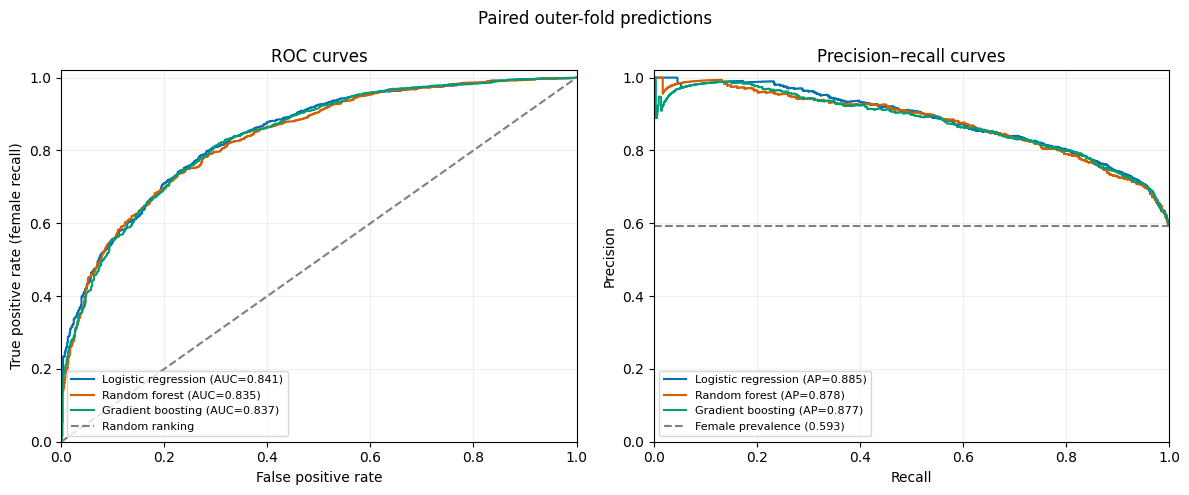

In [ ]:
import matplotlib.pyplot as plt

from sklearn.metrics import roc_curve, precision_recall_curve

COLORS = {
    "Logistic regression": "#0072B2",
    "Random forest": "#D55E00",
    "Gradient boosting": "#009E73"
}

FIGURE_DIR = RUN_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for model_name, slug in model_slugs.items():
    probabilities = outer_predictions[f"p_{slug}"].to_numpy()
    reference = outer_predictions["y"].to_numpy()

    fpr, tpr, _ = roc_curve(reference, probabilities)
    precision, recall, _ = precision_recall_curve(
        reference, probabilities
    )

    auc = model_summary.loc[model_name, "roc_auc"]
    ap = model_summary.loc[model_name, "average_precision"]

    axes[0].plot(
        fpr, tpr,
        color=COLORS[model_name],
        label=f"{model_name} (AUC={auc:.3f})"
    )

    axes[1].step(
        recall, precision,
        where="post",
        color=COLORS[model_name],
        label=f"{model_name} (AP={ap:.3f})"
    )

axes[0].plot(
    [0, 1], [0, 1],
    linestyle="--", color="grey", label="Random ranking"
)

axes[0].set(
    xlabel="False positive rate",
    ylabel="True positive rate (female recall)",
    title="ROC curves"
)

prevalence = outer_predictions["y"].mean()

axes[1].axhline(
    prevalence,
    linestyle="--",
    color="grey",
    label=f"Female prevalence ({prevalence:.3f})"
)

axes[1].set(
    xlabel="Recall",
    ylabel="Precision",
    title="Precision–recall curves"
)

for ax in axes:
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8, loc="lower left")

fig.suptitle("Paired outer-fold predictions", fontsize=12)
fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "roc_pr_curves.png",
    dpi=200, bbox_inches="tight"
)
fig.savefig(
    FIGURE_DIR / "roc_pr_curves.pdf",
    bbox_inches="tight"
)

plt.show()

### Discrimination curves

The ROC and precision–recall curves largely overlap, indicating
similar discrimination across the three model families.

Logistic regression has the highest ROC-AUC (0.8412) and average
precision (0.8852), although the differences are small.

Precision is high when selecting a small subset of birds with
high predicted female probabilities, and decreases as recall increases.
The precision–recall reference line corresponds to the observed
female prevalence of 0.593.

These curves describe discrimination across thresholds.
They do not establish whether the predicted probabilities are
well calibrated.

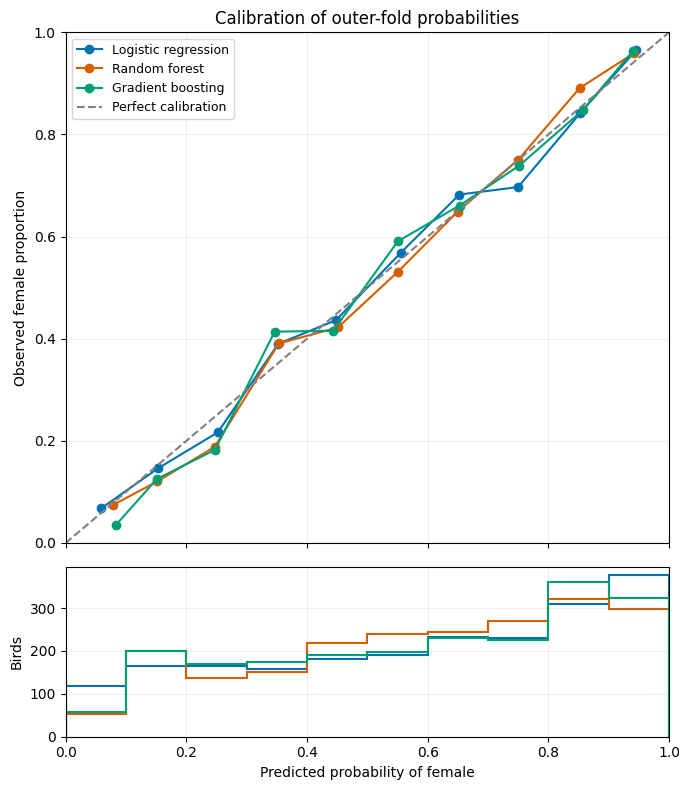

Curve figures and calibration-bin statistics saved.


In [ ]:
n_bins = METRIC_CONFIG["ece_n_bins"]
bin_edges = np.linspace(0, 1, n_bins + 1)

calibration_rows = []

fig, axes = plt.subplots(
    2, 1,
    figsize=(7, 8),
    sharex=True,
    gridspec_kw={"height_ratios": [3, 1]}
)

for model_name, slug in model_slugs.items():
    probabilities = outer_predictions[f"p_{slug}"].to_numpy()
    reference = outer_predictions["y"].to_numpy()

    bin_ids = np.minimum(
        (probabilities * n_bins).astype(int),
        n_bins - 1
    )

    model_rows = []

    for bin_id in range(n_bins):
        mask = bin_ids == bin_id
        count = int(mask.sum())

        row = {
            "model": model_name,
            "bin": bin_id,
            "lower_edge": bin_edges[bin_id],
            "upper_edge": bin_edges[bin_id + 1],
            "n": count,
            "mean_probability": (
                probabilities[mask].mean() if count else np.nan
            ),
            "observed_female_fraction": (
                reference[mask].mean() if count else np.nan
            )
        }

        calibration_rows.append(row)
        model_rows.append(row)

    model_bins = pd.DataFrame(model_rows)
    nonempty = model_bins[model_bins["n"] > 0]

    ece_from_bins = (
        nonempty["n"] / len(reference)
        * (
            nonempty["mean_probability"]
            - nonempty["observed_female_fraction"]
        ).abs()
    ).sum()

    assert np.isclose(
        ece_from_bins,
        model_summary.loc[model_name, "ece"]
    )

    axes[0].plot(
        nonempty["mean_probability"],
        nonempty["observed_female_fraction"],
        marker="o",
        color=COLORS[model_name],
        label=model_name
    )

    axes[1].hist(
        probabilities,
        bins=bin_edges,
        histtype="step",
        linewidth=1.5,
        color=COLORS[model_name]
    )

axes[0].plot(
    [0, 1], [0, 1],
    linestyle="--", color="grey",
    label="Perfect calibration"
)

axes[0].set(
    ylabel="Observed female proportion",
    title="Calibration of outer-fold probabilities",
    ylim=(0, 1)
)
axes[0].legend(fontsize=9)

axes[1].set(
    xlabel="Predicted probability of female",
    ylabel="Birds",
    xlim=(0, 1)
)

for ax in axes:
    ax.grid(alpha=0.2)

fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "calibration_curves.png",
    dpi=200, bbox_inches="tight"
)
fig.savefig(
    FIGURE_DIR / "calibration_curves.pdf",
    bbox_inches="tight"
)

calibration_bins = pd.DataFrame(calibration_rows)
calibration_bins.to_csv(
    RUN_DIR / "calibration_bins.csv",
    index=False
)

plt.show()
print("Curve figures and calibration-bin statistics saved.")

### Calibration results

The calibration curves broadly follow the diagonal, indicating
reasonable agreement between predicted female probabilities
and observed female proportions.

Some local deviations remain. For example, logistic regression
overpredicts female probability in the bin with a mean prediction
near 0.75, where the observed female proportion is approximately 0.70.

The ECE values are 0.0229 for logistic regression, 0.0230 for random
forest and 0.0280 for gradient boosting.

Bin counts are displayed because calibration estimates have
different precision depending on the number of observations.
Without bin-specific uncertainty intervals, local deviations
should not be interpreted as definitive evidence of systematic
miscalibration.

Reasonable calibration does not imply error-free individual
sex assignment.

## 5. Error slices and failure cases

The following descriptive subgroup analyses examine:
- reference-sex groups;
- central versus outer bill-length ranges.

For each outer fold, the central bill-length range is defined by
the 25th and 75th percentiles of the outer training data.
The same boundaries are applied to all model families.

These subgroup analyses are exploratory diagnostics specified after
inspection of aggregate model performance. They do not alter model
settings or decision rules.

Class-specific recall and subgroup Brier scores are reported.
Calibration is not evaluated separately within single-sex groups.

In [ ]:
# Attach measurements using individual identifiers.
slice_data = outer_predictions.merge(
    df[["Ring", "Wing", "Bill", "Tarsus"]],
    on="Ring",
    how="left",
    validate="one_to_one"
)

assert len(slice_data) == len(df)
assert slice_data[FEATURES].notna().all().all()

slice_data["bill_slice"] = ""
bill_boundary_rows = []

# Define boundaries using only each outer training subset.
for fold, (train_idx, valid_idx) in enumerate(
    outer_splits, start=1
):
    lower, upper = X.iloc[train_idx]["Bill"].quantile(
        [0.25, 0.75]
    ).to_numpy()

    fold_mask = slice_data["outer_fold"] == fold

    central = slice_data.loc[fold_mask, "Bill"].between(
        lower, upper, inclusive="both"
    )

    slice_data.loc[fold_mask, "bill_slice"] = np.where(
        central,
        "Central bill range",
        "Outer bill ranges"
    )

    bill_boundary_rows.append({
        "outer_fold": fold,
        "bill_q25": lower,
        "bill_q75": upper
    })

slice_rows = []

for model_name, slug in model_slugs.items():
    for grouping in ["Sex", "bill_slice"]:
        for group_name, subset in slice_data.groupby(grouping):
            reference = subset["y"].to_numpy()
            probabilities = subset[f"p_{slug}"].to_numpy()
            predicted = (probabilities >= 0.50).astype(int)

            tn, fp, fn, tp = confusion_matrix(
                reference, predicted, labels=[0, 1]
            ).ravel()

            slice_rows.append({
                "model": model_name,
                "grouping": grouping,
                "group": group_name,
                "n": len(subset),
                "brier": brier_score_loss(
                    reference, probabilities
                ),
                "error_rate": np.mean(predicted != reference),
                "recall_F": (
                    tp / (tp + fn) if (tp + fn) else np.nan
                ),
                "recall_M": (
                    tn / (tn + fp) if (tn + fp) else np.nan
                )
            })

slice_results = pd.DataFrame(slice_rows)

slice_results.to_csv(
    RUN_DIR / "error_slices.csv",
    index=False
)

pd.DataFrame(bill_boundary_rows).to_csv(
    RUN_DIR / "bill_slice_boundaries.csv",
    index=False
)

print("Reference-sex groups:")
display(
    slice_results[slice_results["grouping"] == "Sex"]
    .drop(columns="grouping")
    .round(4)
)

print("Bill-length groups:")
display(
    slice_results[slice_results["grouping"] == "bill_slice"]
    .drop(columns="grouping")
    .round(4)
)

Reference-sex groups:


,model,group,n,brier,error_rate,recall_F,recall_M
0,Logistic regression,F,1263,0.1200,0.1655,0.8345,NaN
1,Logistic regression,M,867,0.2150,0.3322,NaN,0.6678
4,Random forest,F,1263,0.1210,0.1623,0.8377,NaN
5,Random forest,M,867,0.2216,0.3599,NaN,0.6401
8,Gradient boosting,F,1263,0.1209,0.1655,0.8345,NaN
9,Gradient boosting,M,867,0.2179,0.3287,NaN,0.6713


Bill-length groups:


,model,group,n,brier,error_rate,recall_F,recall_M
2,Logistic regression,Central bill range,1102,0.1906,0.2904,0.8253,0.5226
3,Logistic regression,Outer bill ranges,1028,0.1244,0.1722,0.8454,0.8049
6,Random forest,Central bill range,1102,0.1959,0.2967,0.8209,0.5131
7,Random forest,Outer bill ranges,1028,0.1256,0.1848,0.8574,0.7601
10,Gradient boosting,Central bill range,1102,0.1926,0.2849,0.8179,0.5487
11,Gradient boosting,Outer bill ranges,1028,0.1258,0.1751,0.8540,0.7870


### Subgroup results

All three models classify females more accurately than males.
For logistic regression, the error rate is 16.55% among females
and 33.22% among males.

The central bill-length group is more difficult than the outer
bill-length groups. Logistic regression has an error rate of
29.04% versus 17.22%, respectively. Male recall is particularly
low in the central group: 52.26%, compared with 80.49% in the
outer ranges.

These descriptive associations do not establish the biological
cause of the errors.

The subgroup analysis also limits a universal superiority claim:
although logistic regression has the best overall Brier score,
gradient boosting has a slightly lower classification error rate
in the central bill-length group (28.49% versus 29.04%).
This small difference is descriptive and has not been established
as a reliable subgroup advantage.

The central group contains slightly more than half the birds
because training-fold quantile boundaries are applied inclusively
to validation observations, including tied bill measurements.

### High-confidence errors

A prediction is considered high-confidence when the probability
assigned to the predicted sex is at least 0.90:
P(female) ≥ 0.90 or P(female) ≤ 0.10.

High-confidence errors are retained as individual failure cases.
Their existence does not by itself demonstrate miscalibration:
a high probability is not a guarantee of a correct individual outcome.

The high-confidence subset may contain different birds for each
model, so its error rates are descriptive rather than a comparison
on identical subgroup membership.

In [ ]:
HIGH_CONFIDENCE = 0.90

failure_rows = []
confidence_rows = []

for model_name, slug in model_slugs.items():
    cases = slice_data[
        ["Ring", "Sex", "y", "outer_fold", "Wing", "Bill", "Tarsus"]
    ].copy()

    cases["model"] = model_name
    cases["p_female"] = slice_data[f"p_{slug}"].to_numpy()

    predicted = (cases["p_female"] >= 0.50).astype(int)

    cases["predicted_sex"] = np.where(
        predicted == 1, "F", "M"
    )

    cases["confidence"] = np.maximum(
        cases["p_female"],
        1 - cases["p_female"]
    )

    cases["is_error"] = (
        predicted.to_numpy() != cases["y"].to_numpy()
    )

    cases["failure_type"] = np.select(
        [
            (cases["y"] == 0) & (predicted == 1),
            (cases["y"] == 1) & (predicted == 0)
        ],
        [
            "FP: male classified as female",
            "FN: female classified as male"
        ],
        default="Correct"
    )

    high_confidence = cases["confidence"] >= HIGH_CONFIDENCE

    n_high = int(high_confidence.sum())
    n_high_errors = int(
        (high_confidence & cases["is_error"]).sum()
    )

    confidence_rows.append({
        "model": model_name,
        "total_errors": int(cases["is_error"].sum()),
        "high_confidence_birds": n_high,
        "high_confidence_errors": n_high_errors,
        "error_rate_high_confidence": (
            n_high_errors / n_high if n_high else np.nan
        )
    })

    failure_rows.append(
        cases.loc[cases["is_error"]].copy()
    )

error_cases = pd.concat(failure_rows, ignore_index=True)

confident_errors = (
    error_cases[
        error_cases["confidence"] >= HIGH_CONFIDENCE
    ]
    .sort_values(
        ["model", "confidence", "Ring"],
        ascending=[True, False, True]
    )
)

confidence_summary = pd.DataFrame(confidence_rows)

error_cases.to_csv(
    RUN_DIR / "individual_error_cases.csv",
    index=False
)

confident_errors.to_csv(
    RUN_DIR / "high_confidence_errors.csv",
    index=False
)

confidence_summary.to_csv(
    RUN_DIR / "high_confidence_summary.csv",
    index=False
)

print("High-confidence prediction summary:")
display(confidence_summary.round(4))

print("Three most confident logistic-regression errors:")

lr_examples = confident_errors[
    confident_errors["model"] == "Logistic regression"
].head(3)

display(
    lr_examples[
        [
            "Ring", "Sex", "predicted_sex",
            "p_female", "confidence",
            "Wing", "Bill", "Tarsus"
        ]
    ].round(4)
)

print("Individual failure cases saved.")

High-confidence prediction summary:


,model,total_errors,high_confidence_birds,high_confidence_errors,error_rate_high_confidence
0,Logistic regression,497,496,21,0.0423
1,Random forest,517,351,16,0.0456
2,Gradient boosting,494,382,14,0.0366


Three most confident logistic-regression errors:


,Ring,Sex,predicted_sex,p_female,confidence,Wing,Bill,Tarsus
200,Z062396,F,M,0.0098,0.9902,160,30.5,30.2
86,Z049413,M,F,0.9782,0.9782,178,38.9,31.3
212,Z063154,M,F,0.9755,0.9755,178,38.7,34.9


Individual failure cases saved.


### Individual failure cases

Logistic regression assigns confidence of at least 0.90 to 496 birds,
with 21 errors (4.23%). Corresponding error rates are 4.56% for
random forest and 3.66% for gradient boosting, on different
model-specific subsets.

For example, Z062396 is a DNA-sexed female but receives a predicted
female probability of 0.0098 from logistic regression.
Z049413 and Z063154 are DNA-sexed males with predicted female
probabilities of 0.9782 and 0.9755.

These cases demonstrate that even very confident morphometric
predictions do not guarantee correct individual sex assignment.
They do not, by themselves, demonstrate poor overall calibration
or incorrect reference labels. No records are excluded because
the model disagrees with them.

## 6. Cost- and capacity-based threshold selection

The reference decision scenario uses FP cost = 1, FN cost = 2
and verification capacity = 40%.

For each model and outer fold, candidate thresholds are evaluated
on the retained inner out-of-fold predictions.
The minimum-loss rule is selected using the predefined tie-breaks.

The selected threshold and capacity rule are then applied to the
outer validation birds without using their reference-sex labels.

Capacity is enforced separately within each evaluated batch,
rounding the allowed number of selections down.
When eligible birds exceed capacity, the highest predicted female
probabilities are retained, with Ring breaking probability ties.

The results evaluate fold-specific decision rules.
They do not identify one universal deployment threshold.

In [ ]:
def select_with_capacity(probabilities, rings, threshold, capacity):
    probabilities = np.asarray(probabilities, dtype=float)
    rings = np.asarray(rings, dtype=str)

    limit = int(np.floor(capacity * len(probabilities)))
    selected = np.zeros(len(probabilities), dtype=bool)

    # Sort by descending probability, then ascending Ring.
    order = np.lexsort((rings, -probabilities))
    eligible = order[probabilities[order] >= threshold]

    selected[eligible[:limit]] = True

    assert selected.sum() <= limit
    return selected


def score_selection(reference, selected, fp_cost, fn_cost):
    reference = np.asarray(reference, dtype=int)
    selected = np.asarray(selected, dtype=bool)

    tp = int(((reference == 1) & selected).sum())
    fp = int(((reference == 0) & selected).sum())
    fn = int(((reference == 1) & ~selected).sum())

    return {
        "n": len(reference),
        "n_female": int((reference == 1).sum()),
        "n_selected": int(selected.sum()),
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "loss": fp_cost * fp + fn_cost * fn
    }


def choose_threshold(inner_table, fp_cost, fn_cost, capacity):
    thresholds = list(DECISION_CONFIG["threshold_grid"])

    if DECISION_CONFIG["include_select_none"]:
        # 1.01 encodes the predefined "select no birds" option.
        thresholds.append(1.01)

    rows = []

    for threshold in thresholds:
        selected = select_with_capacity(
            inner_table["p_female"],
            inner_table["Ring"],
            threshold,
            capacity
        )

        rows.append({
            "threshold": threshold,
            **score_selection(
                inner_table["y"],
                selected,
                fp_cost,
                fn_cost
            )
        })

    curve = pd.DataFrame(rows)

    ranked = curve.sort_values(
        ["loss", "n_selected", "threshold"],
        ascending=[True, True, False]
    )

    best = ranked.iloc[0].to_dict()
    return best, curve

In [ ]:
fp_cost = DECISION_CONFIG["false_positive_cost"]
fn_cost = DECISION_CONFIG["false_negative_cost"]
capacity = DECISION_CONFIG["capacity_fraction"]

decision_rows = []
inner_cost_curves = []

selection_predictions = outer_predictions.copy()

for slug in model_slugs.values():
    selection_predictions[f"selected_{slug}"] = False

for model_name, slug in model_slugs.items():
    for fold in range(1, N_OUTER_FOLDS + 1):
        inner_table = inner_predictions[(model_name, fold)]

        # Choose the rule using internal tuning data only.
        best, curve = choose_threshold(
            inner_table, fp_cost, fn_cost, capacity
        )

        curve["model"] = model_name
        curve["outer_fold"] = fold
        inner_cost_curves.append(curve)

        outer_mask = outer_predictions["outer_fold"] == fold
        outer_table = outer_predictions.loc[outer_mask]

        # Selection uses probabilities and identifiers, not true sex.
        selected = select_with_capacity(
            outer_table[f"p_{slug}"],
            outer_table["Ring"],
            best["threshold"],
            capacity
        )

        selection_predictions.loc[
            outer_mask, f"selected_{slug}"
        ] = selected

        # Reference labels are accessed only to score the decision.
        outer_scores = score_selection(
            outer_table["y"],
            selected,
            fp_cost,
            fn_cost
        )

        decision_rows.append({
            "model": model_name,
            "outer_fold": fold,
            "threshold": best["threshold"],
            "select_none": best["threshold"] > 1,
            "inner_n_selected": int(best["n_selected"]),
            "inner_loss": best["loss"],
            **outer_scores
        })

threshold_decisions = pd.DataFrame(decision_rows)
inner_cost_curve_table = pd.concat(
    inner_cost_curves, ignore_index=True
)

# Pool counts across outer evaluation folds.
reference_decision_summary = (
    threshold_decisions.groupby("model", sort=False)[
        ["n", "n_female", "n_selected", "tp", "fp", "fn", "loss"]
    ].sum()
)

reference_decision_summary["selected_fraction"] = (
    reference_decision_summary["n_selected"]
    / reference_decision_summary["n"]
)

reference_decision_summary["precision_selected"] = (
    reference_decision_summary["tp"]
    / reference_decision_summary["n_selected"].replace(0, np.nan)
)

reference_decision_summary["female_recall"] = (
    reference_decision_summary["tp"]
    / reference_decision_summary["n_female"]
)

reference_decision_summary["loss_per_100"] = (
    100 * reference_decision_summary["loss"]
    / reference_decision_summary["n"]
)

threshold_decisions.to_csv(
    RUN_DIR / "threshold_decisions_reference.csv",
    index=False
)
inner_cost_curve_table.to_csv(
    RUN_DIR / "inner_cost_curves_reference.csv",
    index=False
)
selection_predictions.to_csv(
    RUN_DIR / "selection_predictions_reference.csv",
    index=False
)
reference_decision_summary.to_csv(
    RUN_DIR / "decision_summary_reference.csv"
)

print("Thresholds chosen using internal predictions:")
display(
    threshold_decisions[
        ["model", "outer_fold", "threshold", "inner_n_selected"]
    ].round(4)
)

print("Decision performance on outer validation birds:")
display(
    reference_decision_summary[
        [
            "n_selected",
            "selected_fraction",
            "precision_selected",
            "female_recall",
            "fp",
            "fn",
            "loss_per_100"
        ]
    ].round(4)
)

Thresholds chosen using internal predictions:


,model,outer_fold,threshold,inner_n_selected
0,Logistic regression,1,0.73,681
1,Logistic regression,2,0.71,681
2,Logistic regression,3,0.72,681
3,Logistic regression,4,0.72,681
4,Logistic regression,5,0.73,681
5,Random forest,1,0.72,680
6,Random forest,2,0.71,681
7,Random forest,3,0.71,681
8,Random forest,4,0.70,681
9,Random forest,5,0.70,681


Decision performance on outer validation birds:


,n_selected,selected_fraction,precision_selected,female_recall,fp,fn,loss_per_100
model,,,,,,,
Logistic regression,823,0.3864,0.8858,0.5772,94,534,54.5540
Random forest,825,0.3873,0.8873,0.5796,93,531,54.2254
Gradient boosting,820,0.3850,0.8817,0.5724,97,540,55.2582


### Reference decision results

Internally selected thresholds range from 0.71–0.73 for logistic
regression, 0.70–0.72 for random forest and 0.72–0.73 for gradient
boosting. These thresholds operate together with the capacity rule.

On outer validation birds, logistic regression selects 823 birds,
including 729 females. Random forest selects 825 birds, including
732 females, and gradient boosting selects 820 birds, including
723 females.

The corresponding losses are 54.5540, 54.2254 and 55.2582 units
per 100 birds. Random forest has the lowest observed decision loss,
despite logistic regression having the lowest overall Brier score.
The advantage over logistic regression is small and descriptive.

Actual selection fractions are below the 40% ceiling because the
threshold can leave some verification capacity unused.
The capacity constraint also limits achievable female recall.

## 7. Cost curves and sensitivity analysis

The cost curves summarize internal tuning loss and workload across
candidate thresholds, averaged over the five outer training subsets.
They are not independent validation performance estimates.

Sensitivity analysis varies the false-negative cost across
0.5, 1, 2 and 5, and verification capacity across 20%, 40% and 60%.
The false-positive cost remains 1.

For every scenario, model and outer fold, the decision rule is selected
using inner predictions and evaluated on the outer validation birds.
Model configurations and probability predictions remain unchanged.

Model comparisons are made within each scenario.
Loss values from scenarios with different costs use different
valuation assumptions and should not be directly ranked together.

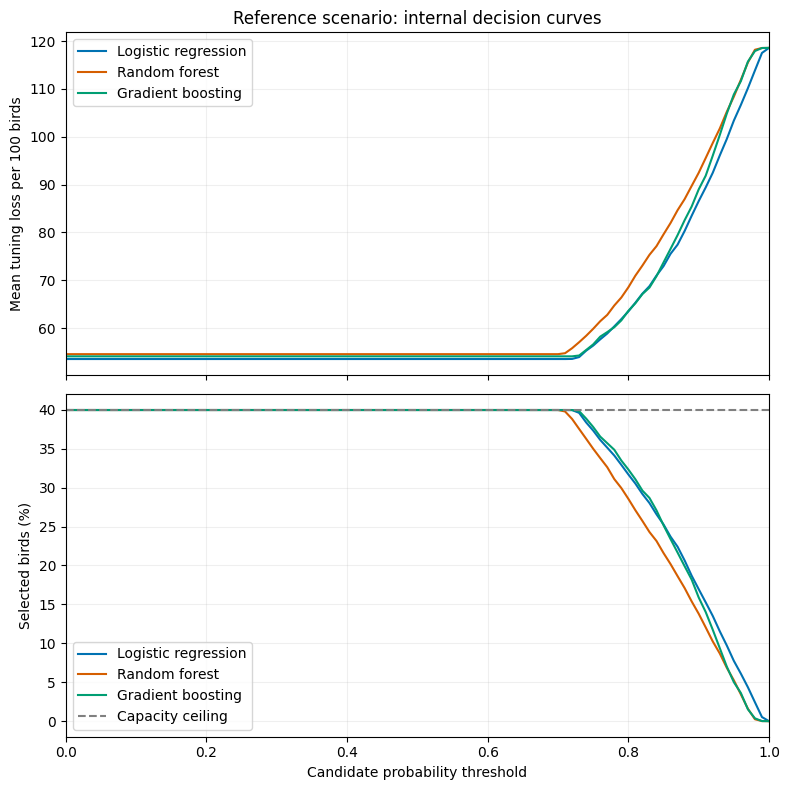

In [ ]:
curve_data = inner_cost_curve_table[
    inner_cost_curve_table["threshold"] <= 1
].copy()

curve_data["loss_per_100"] = (
    100 * curve_data["loss"] / curve_data["n"]
)
curve_data["selected_percent"] = (
    100 * curve_data["n_selected"] / curve_data["n"]
)

mean_curves = (
    curve_data.groupby(["model", "threshold"], as_index=False)[
        ["loss_per_100", "selected_percent"]
    ].mean()
)

fig, axes = plt.subplots(2, 1, figsize=(8, 8), sharex=True)

for model_name in model_slugs:
    subset = mean_curves[mean_curves["model"] == model_name]

    axes[0].plot(
        subset["threshold"],
        subset["loss_per_100"],
        color=COLORS[model_name],
        label=model_name
    )

    axes[1].plot(
        subset["threshold"],
        subset["selected_percent"],
        color=COLORS[model_name],
        label=model_name
    )

axes[0].set(
    ylabel="Mean tuning loss per 100 birds",
    title="Reference scenario: internal decision curves"
)
axes[0].legend()

axes[1].axhline(
    100 * DECISION_CONFIG["capacity_fraction"],
    linestyle="--",
    color="grey",
    label="Capacity ceiling"
)
axes[1].set(
    xlabel="Candidate probability threshold",
    ylabel="Selected birds (%)",
    xlim=(0, 1)
)
axes[1].legend()

for ax in axes:
    ax.grid(alpha=0.2)

fig.tight_layout()

for extension in ["png", "pdf"]:
    fig.savefig(
        FIGURE_DIR / f"reference_cost_curves.{extension}",
        dpi=200,
        bbox_inches="tight"
    )

mean_curves.to_csv(
    RUN_DIR / "mean_inner_cost_curves.csv",
    index=False
)

plt.show()

In [ ]:
sensitivity_rows = []
sensitivity_curve_tables = []

scenario_number = 0

for scenario_fn_cost in SENSITIVITY_CONFIG["false_negative_costs"]:
    for scenario_capacity in SENSITIVITY_CONFIG["capacity_fractions"]:
        scenario_number += 1
        scenario_fp_cost = SENSITIVITY_CONFIG["false_positive_cost"]

        print(
            f"Scenario {scenario_number}/12: "
            f"FN cost={scenario_fn_cost}, "
            f"capacity={scenario_capacity:.0%}",
            flush=True
        )

        for model_name, slug in model_slugs.items():
            for fold in range(1, N_OUTER_FOLDS + 1):
                inner_table = inner_predictions[(model_name, fold)]

                best, curve = choose_threshold(
                    inner_table,
                    scenario_fp_cost,
                    scenario_fn_cost,
                    scenario_capacity
                )

                curve = curve.assign(
                    model=model_name,
                    outer_fold=fold,
                    fp_cost=scenario_fp_cost,
                    fn_cost=scenario_fn_cost,
                    capacity_fraction=scenario_capacity
                )
                sensitivity_curve_tables.append(curve)

                outer_table = outer_predictions[
                    outer_predictions["outer_fold"] == fold
                ]

                selected = select_with_capacity(
                    outer_table[f"p_{slug}"],
                    outer_table["Ring"],
                    best["threshold"],
                    scenario_capacity
                )

                scores = score_selection(
                    outer_table["y"],
                    selected,
                    scenario_fp_cost,
                    scenario_fn_cost
                )

                sensitivity_rows.append({
                    "model": model_name,
                    "outer_fold": fold,
                    "fp_cost": scenario_fp_cost,
                    "fn_cost": scenario_fn_cost,
                    "capacity_fraction": scenario_capacity,
                    "threshold": best["threshold"],
                    "select_none": best["threshold"] > 1,
                    "inner_loss": best["loss"],
                    **scores
                })

sensitivity_decisions = pd.DataFrame(sensitivity_rows)

group_columns = [
    "model", "fp_cost", "fn_cost", "capacity_fraction"
]

sensitivity_summary = (
    sensitivity_decisions.groupby(group_columns, as_index=False)[
        ["n", "n_female", "n_selected", "tp", "fp", "fn", "loss"]
    ].sum()
)

sensitivity_summary["loss_per_100"] = (
    100 * sensitivity_summary["loss"]
    / sensitivity_summary["n"]
)
sensitivity_summary["selected_fraction"] = (
    sensitivity_summary["n_selected"]
    / sensitivity_summary["n"]
)
sensitivity_summary["precision_selected"] = (
    sensitivity_summary["tp"]
    / sensitivity_summary["n_selected"].replace(0, np.nan)
)
sensitivity_summary["female_recall"] = (
    sensitivity_summary["tp"]
    / sensitivity_summary["n_female"]
)

# Verify that the reference scenario reproduces previous results.
reference_check = (
    sensitivity_summary[
        (sensitivity_summary["fn_cost"] == fn_cost)
        & (sensitivity_summary["capacity_fraction"] == capacity)
    ]
    .set_index("model")
)

check_columns = ["n_selected", "tp", "fp", "fn", "loss"]

pd.testing.assert_frame_equal(
    reference_check[check_columns].sort_index(),
    reference_decision_summary[check_columns].sort_index(),
    check_dtype=False
)

cost_comparison = sensitivity_summary.pivot(
    index=["fn_cost", "capacity_fraction"],
    columns="model",
    values="loss_per_100"
)

# Preserve ties rather than arbitrarily declaring one winner.
observed_best = cost_comparison.apply(
    lambda row: ", ".join(
        row.index[
            np.isclose(row, row.min(), rtol=0, atol=1e-10)
        ]
    ),
    axis=1
)

cost_comparison["lowest_observed_loss_model"] = observed_best

sensitivity_decisions.to_csv(
    RUN_DIR / "sensitivity_threshold_decisions.csv",
    index=False
)
sensitivity_summary.to_csv(
    RUN_DIR / "sensitivity_summary.csv",
    index=False
)
pd.concat(sensitivity_curve_tables, ignore_index=True).to_csv(
    RUN_DIR / "sensitivity_inner_cost_curves.csv",
    index=False
)
cost_comparison.to_csv(
    RUN_DIR / "sensitivity_cost_comparison.csv"
)

print("\nOuter validation loss per 100 birds:")
display(cost_comparison.round(4))

print("Reference scenario reproduced successfully.")
print("Sensitivity results saved.")

Scenario 1/12: FN cost=0.5, capacity=20%
Scenario 2/12: FN cost=0.5, capacity=40%
Scenario 3/12: FN cost=0.5, capacity=60%
Scenario 4/12: FN cost=1.0, capacity=20%
Scenario 5/12: FN cost=1.0, capacity=40%
Scenario 6/12: FN cost=1.0, capacity=60%
Scenario 7/12: FN cost=2.0, capacity=20%
Scenario 8/12: FN cost=2.0, capacity=40%
Scenario 9/12: FN cost=2.0, capacity=60%
Scenario 10/12: FN cost=5.0, capacity=20%
Scenario 11/12: FN cost=5.0, capacity=40%
Scenario 12/12: FN cost=5.0, capacity=60%

Outer validation loss per 100 birds:


model                      Gradient boosting  Logistic regression  \
fn_cost capacity_fraction                                           
0.5     0.2                          21.5258              20.9390   
        0.4                          17.2770              17.0657   
        0.6                          17.0892              17.3709   
1.0     0.2                          41.9249              41.0798   
        0.4                          29.9061              29.7183   
        0.6                          23.8028              23.5211   
2.0     0.2                          82.7230              81.3615   
        0.4                          55.2582              54.5540   
        0.6                          35.6808              35.4460   
5.0     0.2                         205.1174             202.2066   
        0.4                         131.3146             129.7653   
        0.6                          71.3146              71.0798   

model                      Random forest lowest_observed_loss_model  
fn_cost capacity_fraction                                            
0.5     0.2                      21.5023        Logistic regression  
        0.4                      16.9014              Random forest  
        0.6                      16.9249              Random forest  
1.0     0.2                      41.9718        Logistic regression  
        0.4                      29.2958              Random forest  
        0.6                      24.3662        Logistic regression  
2.0     0.2                      82.9108        Logistic regression  
        0.4                      54.2254              Random forest  
        0.6                      36.5728        Logistic regression  
5.0     0.2                     205.7277        Logistic regression  
        0.4                     129.0141              Random forest  
        0.6                      73.6150        Logistic regression

Reference scenario reproduced successfully.
Sensitivity results saved.


### Sensitivity results

The model with the lowest observed decision loss depends on the
resource constraint.

Logistic regression has the lowest loss in all four scenarios
with 20% verification capacity. Random forest has the lowest loss
in all four scenarios with 40% capacity.

At 60% capacity, random forest has the lowest loss when FN cost
is 0.5, while logistic regression has the lowest loss for FN costs
of 1, 2 and 5.

These comparisons are descriptive. The scenarios are related
analyses of the same observations, not independent replications.

The reference cost curves have a broad plateau at lower thresholds
because the capacity constraint retains the same highest-ranked
birds. Above approximately 0.70, selection decreases and missed
females become more costly.

The threshold must therefore be interpreted together with the
ranking and capacity rules. There is no universally best model
or threshold across all examined objectives.

## 8. Final model and threshold decision record

Logistic regression is retained as the primary probability model,
following the predefined primary comparison metric, Brier score.

This choice does not imply minimum decision loss in every scenario:
random forest had slightly lower observed loss in the reference
cost-and-capacity scenario.

After evaluation, the final logistic model is developed using
all 2,130 birds. The same six configurations and three-fold
stratified tuning procedure are used.

A single final threshold is selected from internal out-of-fold
probabilities using the predefined reference costs, capacity
constraint and tie-breaks.

This is a finalization fit for potential future use.
Its development predictions are not an independent performance
assessment. The exact finalized model and threshold have not
been evaluated on a new external dataset.

In [ ]:
import joblib

FINAL_MODEL_NAME = "Logistic regression"

FINAL_DIR = RUN_DIR / "final_model"
FINAL_DIR.mkdir(parents=True, exist_ok=True)

final_cv = StratifiedKFold(
    n_splits=N_INNER_FOLDS,
    shuffle=True,
    random_state=SEED
)
final_cv_splits = list(final_cv.split(X, y))

with warnings.catch_warnings(record=True) as final_warnings:
    warnings.simplefilter("always")

    final_search = GridSearchCV(
        estimator=clone(models[FINAL_MODEL_NAME]),
        param_grid=param_grids[FINAL_MODEL_NAME],
        scoring=TUNING_SCORING,
        cv=final_cv_splits,
        refit=True,
        n_jobs=1,
        error_score="raise"
    )

    final_search.fit(X, y)

    assert np.array_equal(
        final_search.best_estimator_.classes_,
        np.array([0, 1])
    )

    final_tuning_probabilities = cross_val_predict(
        clone(final_search.best_estimator_),
        X,
        y,
        cv=final_cv_splits,
        method="predict_proba",
        n_jobs=1
    )[:, 1]

final_tuning_table = metadata.copy()
final_tuning_table["y"] = y.to_numpy()
final_tuning_table["p_female"] = final_tuning_probabilities

final_rule, final_cost_curve = choose_threshold(
    final_tuning_table,
    DECISION_CONFIG["false_positive_cost"],
    DECISION_CONFIG["false_negative_cost"],
    DECISION_CONFIG["capacity_fraction"]
)

final_decision_record = {
    "model": FINAL_MODEL_NAME,
    "selection_basis": "Primary comparison metric: Brier score",
    "features": FEATURES,
    "positive_class": "female",
    "data_sha256": data_sha256,
    "sklearn_version": sklearn.__version__,
    "best_parameters": final_search.best_params_,
    "threshold": float(final_rule["threshold"]),
    "select_none": bool(final_rule["threshold"] > 1),
    "decision_configuration": DECISION_CONFIG,
    "development_n_selected": int(final_rule["n_selected"]),
    "evaluation_scope": (
        "Finalization on all available data; no new external evaluation."
    )
}

joblib.dump(
    final_search.best_estimator_,
    FINAL_DIR / "logistic_regression.joblib"
)

pd.DataFrame(final_search.cv_results_).to_csv(
    FINAL_DIR / "final_search_results.csv",
    index=False
)
final_tuning_table.to_csv(
    FINAL_DIR / "final_development_predictions.csv",
    index=False
)
final_cost_curve.to_csv(
    FINAL_DIR / "final_development_cost_curve.csv",
    index=False
)

with open(
    FINAL_DIR / "threshold_decision_record.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(final_decision_record, file, indent=2)

with open(
    FINAL_DIR / "warnings.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        [
            {
                "category": item.category.__name__,
                "message": str(item.message)
            }
            for item in final_warnings
        ],
        file,
        indent=2
    )

print("Final model:", FINAL_MODEL_NAME)
print("Selected parameters:", final_search.best_params_)
print("Final threshold:", final_rule["threshold"])
print("Capacity ceiling:", DECISION_CONFIG["capacity_fraction"])
print("Warnings recorded:", len(final_warnings))
print("Final model and decision record saved.")

Final model: Logistic regression
Selected parameters: {'model__C': 0.1}
Final threshold: 0.71
Capacity ceiling: 0.4
Warnings recorded: 22
Final model and decision record saved.


### Final decision record

The finalized model is logistic regression with C = 0.1.
The selected female-probability threshold is 0.71.

For the reference scenario:
- birds with P(female) ≥ 0.71 are eligible for DNA confirmation;
- no more than 40% of a batch are selected, rounding down;
- if eligibility exceeds capacity, the highest probabilities are retained;
- Ring identifier in ascending order breaks probability ties.

Non-selection is not a definitive male classification.

The final model and threshold were developed using all available data.
Their performance has not been assessed on a new external dataset.

## 9. Conclusions and limitations

Logistic regression provides a strong simple baseline for predicting
adult Red Knot sex from Wing, Bill and Tarsus. It has the lowest
outer-fold Brier score (0.1586), with ROC-AUC of 0.8412 and average
precision of 0.8852. More complex models do not consistently improve
the results.

Calibration is reasonably close to the diagonal, but individual
predictions remain imperfect. Errors are more frequent among males
and birds in the central bill-length range. High-confidence errors
occur in all three model families.

Probability quality and decision utility lead to different rankings.
Random forest has slightly lower observed loss in the reference
cost-and-capacity scenario, while sensitivity analysis shows that
the lowest-loss model changes with the assumed resources and costs.

The main limitations are:

- The dataset was previously examined in DS-A3.
- Random individual folds evaluate the same sampling framework,
  not transfer to a new population or future sampling period.
- Bootstrap intervals are approximate and conditional on the
  existing predictions, without model refitting.
- ECE depends on the chosen binning; local calibration deviations
  are shown without bin-specific uncertainty intervals.
- Subgroup diagnostics are exploratory.
- Costs and verification capacity are hypothetical.
- The final model and threshold require external validation before
  being treated as a generally reliable operational procedure.